### A Analogia Perfeita para um Arquiteto

Imagine que você precisa classificar um novo edifício histórico que acabou de ser descoberto. Como você faria?

Provavelmente compararia com os **edifícios mais parecidos que você já conhece** e diria: "*se os 5 vizinhos mais similares são Art Déco, provavelmente esse também é.*"

É exatamente assim que o KNN (K-Nearest Neighbors / K-Vizinhos Mais Próximos) funciona!

1. Importações

In [47]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

Aqui você está trazendo três "ferramentas" da biblioteca **scikit-learn**:

* `load_iris`: Carrega um dataset famoso com dados de flores
* `KNeighborsClassifier`: O algoritmo KNN em si
* `train_test_split`: Função que divide os dados em treino e teste

2. Carregando os Dados

In [48]:
X, y = load_iris(return_X_y=True)

O **dataset Iris** é o "Olá Mundo" do Machine Learning. Ele contém medições de **150 flores** (comprimento e largura de pétalas e sépalas) e a espécie de cada uma.

* `X` → As características (medidas das flores) — "*o que o modelo vai observar*"
* `y` → Os rótulos (espécies: 0, 1 ou 2) — "*a resposta correta*"

3. Dividindo os Dados

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.50, random_state=42)

Aqui os dados são divididos em **dois grupos**:

* **Treino (50%)** → O modelo estuda esses exemplos
* **Teste (50%)** → Usamos esses para avaliar se ele aprendeu


> 💡 **Analogia**: É como estudar com metade das questões de uma prova e depois ser testado com a outra metade que você nunca viu.

O `random_state=42` garante que a divisão seja sempre a mesma toda vez que você rodar o código (reprodutibilidade).

4. Criando e Treinando o Modelo

In [50]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

* `KNeighborsClassifier()` → Cria o modelo. Sem parâmetros, usa **k=5** por padrão (analisa os 5 vizinhos mais próximos)
* `.fit()` → O modelo "memoriza" os dados de treino

5. Fazendo Previsões

In [51]:
y_pred = knn.predict(X_test)

O modelo olha para cada flor do conjunto de teste, encontra as **5 flores mais parecidas** no conjunto de treino, e vota: "*qual é a espécie mais comum entre os vizinhos?*"

### Como Ver os Resultados? 📊

Acurácia do modelo: 94.67%

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        29
  versicolor       0.85      1.00      0.92        23
   virginica       1.00      0.83      0.90        23

    accuracy                           0.95        75
   macro avg       0.95      0.94      0.94        75
weighted avg       0.95      0.95      0.95        75



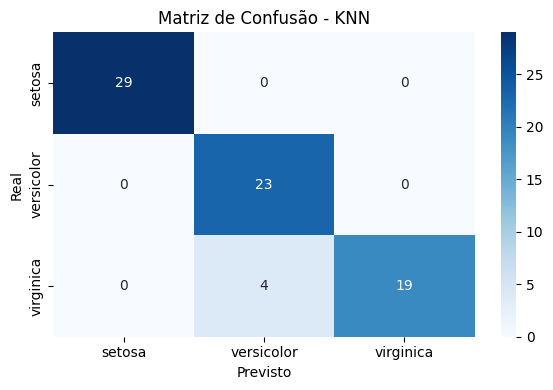

In [52]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Acurácia geral — percentual de acertos
print(f"Acurácia do modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# 2. Relatório completo por classe — precisão, recall e F1-score
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred,
      target_names=['setosa', 'versicolor', 'virginica']))

# 3. Matriz de confusão — mostra onde o modelo errou
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["setosa", "versicolor", "virginica"],
            yticklabels=["setosa", "versicolor", "virginica"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão - KNN")
plt.tight_layout()
plt.show()

**O que cada resultado significa?**

| Métrica | O que mede |
| --- | --- |
| Acurácia | % de acertos no total |
| Precision | Das vezes que disse "é X", quantas estava certo? |
| Recall | De todos os X reais, quantos ele encontrou? |
| Matriz de Confusão | Mostra visualmente onde o modelo acertou e errou |

### 🎯 Desafio para você:

> Tente mudar o `test_size=0.50` para `0.30` e o `KNeighborsClassifier()` para `KNeighborsClassifier(n_neighbors=3)`. O que muda na acurácia? Isso é uma excelente forma de desenvolver intuição sobre o algoritmo!